# Phân đoạn mẫu thử bằng model đã train

Đặt cạnh `train.ipynb` trong thư mục `model/`. Chạy **từ trên xuống**, mỗi bước một cell:

| Bước | Việc | Bạn cần làm gì |
|---|---|---|
| 0 | Cài thư viện, dò đường dẫn | Chỉ đổi `DRIVE_ROOT` nếu đường dẫn Drive khác |
| 1 | Nạp model từ `model/checkpoints/` | Tùy chọn: điền `CKPT_NAME` |
| 2 | **Chọn mẫu** | **Điền `PID` và `Z_LIST`** (chỉ sửa ở đây) |
| 3 | **Model dự đoán** đúng các lát đã chọn | Không sửa |
| 4 | **Hiển thị** kết quả | Không sửa |
| 5 | (Tùy chọn) Dự đoán cả volume và lưu file | Không sửa |

Mỗi hình ở bước 4 có 4 cột: ảnh CT, nhãn thật, **dự đoán của model**, và hình chồng so sánh.

## Bước 0. Cài thư viện và dò đường dẫn

In [1]:
!pip install timm einops pyyaml tqdm matplotlib scipy -q
print('Cài xong thư viện')

Cài xong thư viện


In [2]:
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # ĐỔI nếu đường dẫn Drive của bạn khác (giống train.ipynb)
    DRIVE_ROOT = Path('/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES')
    MODEL_DIR = DRIVE_ROOT / 'model'
    DATA_DIR = DRIVE_ROOT / 'data' / 'processed'
else:
    MODEL_DIR = Path.cwd()                       # notebook nằm trong model/
    DATA_DIR = MODEL_DIR.parent / 'data' / 'processed'

CONFIG_PATH = MODEL_DIR / 'configs' / 'train_config.yaml'
VOL_DIR = DATA_DIR / 'volumes'
for p in [str(MODEL_DIR), str(MODEL_DIR / 'third_party' / 'MambaVision')]:
    if p not in sys.path:
        sys.path.insert(0, p)

assert CONFIG_PATH.exists(), 'Không thấy config: ' + str(CONFIG_PATH)
assert VOL_DIR.exists(), 'Không thấy thư mục volumes: ' + str(VOL_DIR)
print('MODEL_DIR:', MODEL_DIR)
print('VOL_DIR  :', VOL_DIR)

Mounted at /content/drive
MODEL_DIR: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model
VOL_DIR  : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/processed/volumes


## Bước 1. Nạp model từ checkpoint

In [3]:
import yaml, torch, numpy as np
import matplotlib.pyplot as plt
from src.models import build_model

with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)
config['MODEL']['pretrained'] = False      # trọng số lấy từ checkpoint, không cần tải ImageNet

CKPT_DIR = MODEL_DIR / 'checkpoints'
ckpts = sorted(CKPT_DIR.glob('*.pth'), key=lambda p: p.stat().st_mtime)
print('Các checkpoint có sẵn trong', CKPT_DIR)
for p in ckpts:
    print('   ', p.name, '|', round(p.stat().st_size / 1e6, 1), 'MB')
assert ckpts, 'Chưa có file .pth nào trong checkpoints/'

# ĐỔI (tùy chọn): điền tên file, ví dụ 'mamba_unet_best.pth'. None = tự chọn *_best.pth, không có thì file mới nhất
CKPT_NAME = None
if CKPT_NAME:
    CKPT_PATH = CKPT_DIR / CKPT_NAME
else:
    best = [p for p in ckpts if p.name.endswith('_best.pth')]
    CKPT_PATH = best[-1] if best else ckpts[-1]

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = build_model(config)
ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
state = ckpt['model_state_dict'] if isinstance(ckpt, dict) and 'model_state_dict' in ckpt else ckpt
missing, unexpected = model.load_state_dict(state, strict=False)
model.to(DEVICE).eval()

print('\n=> MODEL ĐANG DÙNG:', CKPT_PATH.name, '| thiết bị:', DEVICE)
if isinstance(ckpt, dict) and 'epoch' in ckpt:
    print('   Lưu ở epoch', ckpt['epoch'], '| val_dice lúc lưu:', ckpt.get('val_dice'))
if missing or unexpected:
    print('\n!! CẢNH BÁO: kiến trúc code hiện tại KHÁC checkpoint, kết quả có thể sai')
    print('   Thiếu key:', len(missing), missing[:5])
    print('   Thừa key :', len(unexpected), unexpected[:5])
else:
    print('   Khớp hoàn toàn giữa code và checkpoint')

Các checkpoint có sẵn trong /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model/checkpoints
    mamba_unet_baseline_final_weights.pth | 153.0 MB
[MambaUNet] Khởi tạo thành công: backbone=mamba_vision_T, pretrained=False
[MambaUNet] Thiết bị: cuda

=> MODEL ĐANG DÙNG: mamba_unet_baseline_final_weights.pth | thiết bị: cuda
   Khớp hoàn toàn giữa code và checkpoint


## Bước 2. Chọn mẫu (CHỈ SỬA Ở CELL NÀY)

- `PID`: mã bệnh nhân, ví dụ `'LIDC-IDRI-0005'`. Bệnh nhân nào có file trong `volumes/` đều được, không cần thuộc tập test.
- `Z_LIST`: các lát muốn dự đoán, ví dụ `[120, 121, 125]`. Để `None` thì tự lấy tối đa 4 lát có nốt thật.
- Chạy cell xong sẽ in ra danh sách các lát có nốt thật để bạn chọn.

In [16]:
# ===================== CHỌN MẪU Ở ĐÂY =====================
PID = 'LIDC-IDRI-0035'     # ĐỔI: mã bệnh nhân
Z_LIST = None              # ĐỔI: ví dụ [120, 121, 125]; None = tự lấy các lát có nốt thật
THRESH = 0.5               # ngưỡng xác suất để coi là nốt
# ==========================================================

all_pids = sorted(p.name.replace('_img.npy', '') for p in VOL_DIR.glob('*_img.npy'))
print('Số bệnh nhân có file trong volumes/:', len(all_pids), '| ví dụ:', all_pids[:5])
assert PID in all_pids, 'Không có bệnh nhân ' + PID + ' trong volumes/'

vol = np.load(VOL_DIR / (PID + '_img.npy'), mmap_mode='r')
votes = np.load(VOL_DIR / (PID + '_votes.npy'), mmap_mode='r')
Z, H, W = vol.shape
S = config['DATA'].get('image_size', 256)
assert H >= S and W >= S, 'Ảnh nhỏ hơn image_size'
T0, L0 = (H - S) // 2, (W - S) // 2          # CenterCrop giống lúc val/test (cùng cách train.ipynb dùng)
VOTE_TH = config['DATA'].get('positive_votes_threshold', 2)

def crop(a):
    return a[..., T0:T0 + S, L0:L0 + S]

gt_vol = np.asarray(crop(votes)) >= VOTE_TH                       # (Z, S, S) nhãn thật
nodule_z = [int(z) for z in np.where(gt_vol.reshape(Z, -1).any(1))[0]]

print('\n' + PID, '| số lát:', Z, '(z từ 0 đến', str(Z - 1) + ')')
print('Các lát có nốt thật (sau khi cắt giữa ảnh):', nodule_z if nodule_z else 'KHÔNG CÓ')

if Z_LIST is None:
    Z_LIST = nodule_z[:4]
Z_LIST = [int(z) for z in Z_LIST if 0 <= int(z) < Z]
assert Z_LIST, 'Chưa có lát nào để dự đoán. Bệnh nhân này không có nốt, hãy tự điền Z_LIST.'
print('\n=> SẼ DỰ ĐOÁN CÁC LÁT:', Z_LIST)

Số bệnh nhân có file trong volumes/: 983 | ví dụ: ['LIDC-IDRI-0001', 'LIDC-IDRI-0002', 'LIDC-IDRI-0003', 'LIDC-IDRI-0004', 'LIDC-IDRI-0005']

LIDC-IDRI-0035 | số lát: 222 (z từ 0 đến 221)
Các lát có nốt thật (sau khi cắt giữa ảnh): [192, 193, 194, 195]

=> SẼ DỰ ĐOÁN CÁC LÁT: [192, 193, 194, 195]


## Bước 3. Model dự đoán các lát đã chọn

In [17]:
@torch.no_grad()
def predict_slice(z):
    # Ghép 3 lát (z-1, z, z+1) thành 3 kênh như lúc train, cắt giữa ảnh, đưa qua model
    x = np.stack([vol[max(z - 1, 0)], vol[z], vol[min(z + 1, Z - 1)]])
    x = torch.from_numpy(np.ascontiguousarray(crop(x))).float()[None].to(DEVICE)
    return model(x)[0, 0].float().cpu().numpy()          # xác suất 0..1, model đã có Sigmoid

def dice_np(gt, pb):
    gt, pb = gt.astype(bool), pb.astype(bool)
    if gt.sum() == 0 and pb.sum() == 0:
        return 1.0
    return float(2.0 * (gt & pb).sum() / (gt.sum() + pb.sum()))

results = {}   # z -> dict(img, gt, prob, pred, dice)
for z in Z_LIST:
    prob = predict_slice(z)
    pred = prob >= THRESH
    results[z] = dict(img=np.asarray(crop(vol[z]), dtype=np.float32), gt=gt_vol[z],
                      prob=prob, pred=pred, dice=dice_np(gt_vol[z], pred))

print('Model:', CKPT_PATH.name, '| Bệnh nhân:', PID, '| ngưỡng:', THRESH)
print('%-6s %-12s %-14s %s' % ('z', 'px nhãn thật', 'px model dự đoán', 'Dice'))
for z, r in results.items():
    print('%-6d %-12d %-14d %.3f' % (z, r['gt'].sum(), r['pred'].sum(), r['dice']))

Model: mamba_unet_baseline_final_weights.pth | Bệnh nhân: LIDC-IDRI-0035 | ngưỡng: 0.5
z      px nhãn thật px model dự đoán Dice
192    56           52             0.815
193    56           48             0.865
194    33           32             0.769
195    33           0              0.000


## Bước 4. Hiển thị kết quả

Mỗi hàng là một lát. Cột 3 là **đầu ra của model**. Cột 4 chồng nhãn thật (xanh) và dự đoán của model (đỏ) lên ảnh CT.

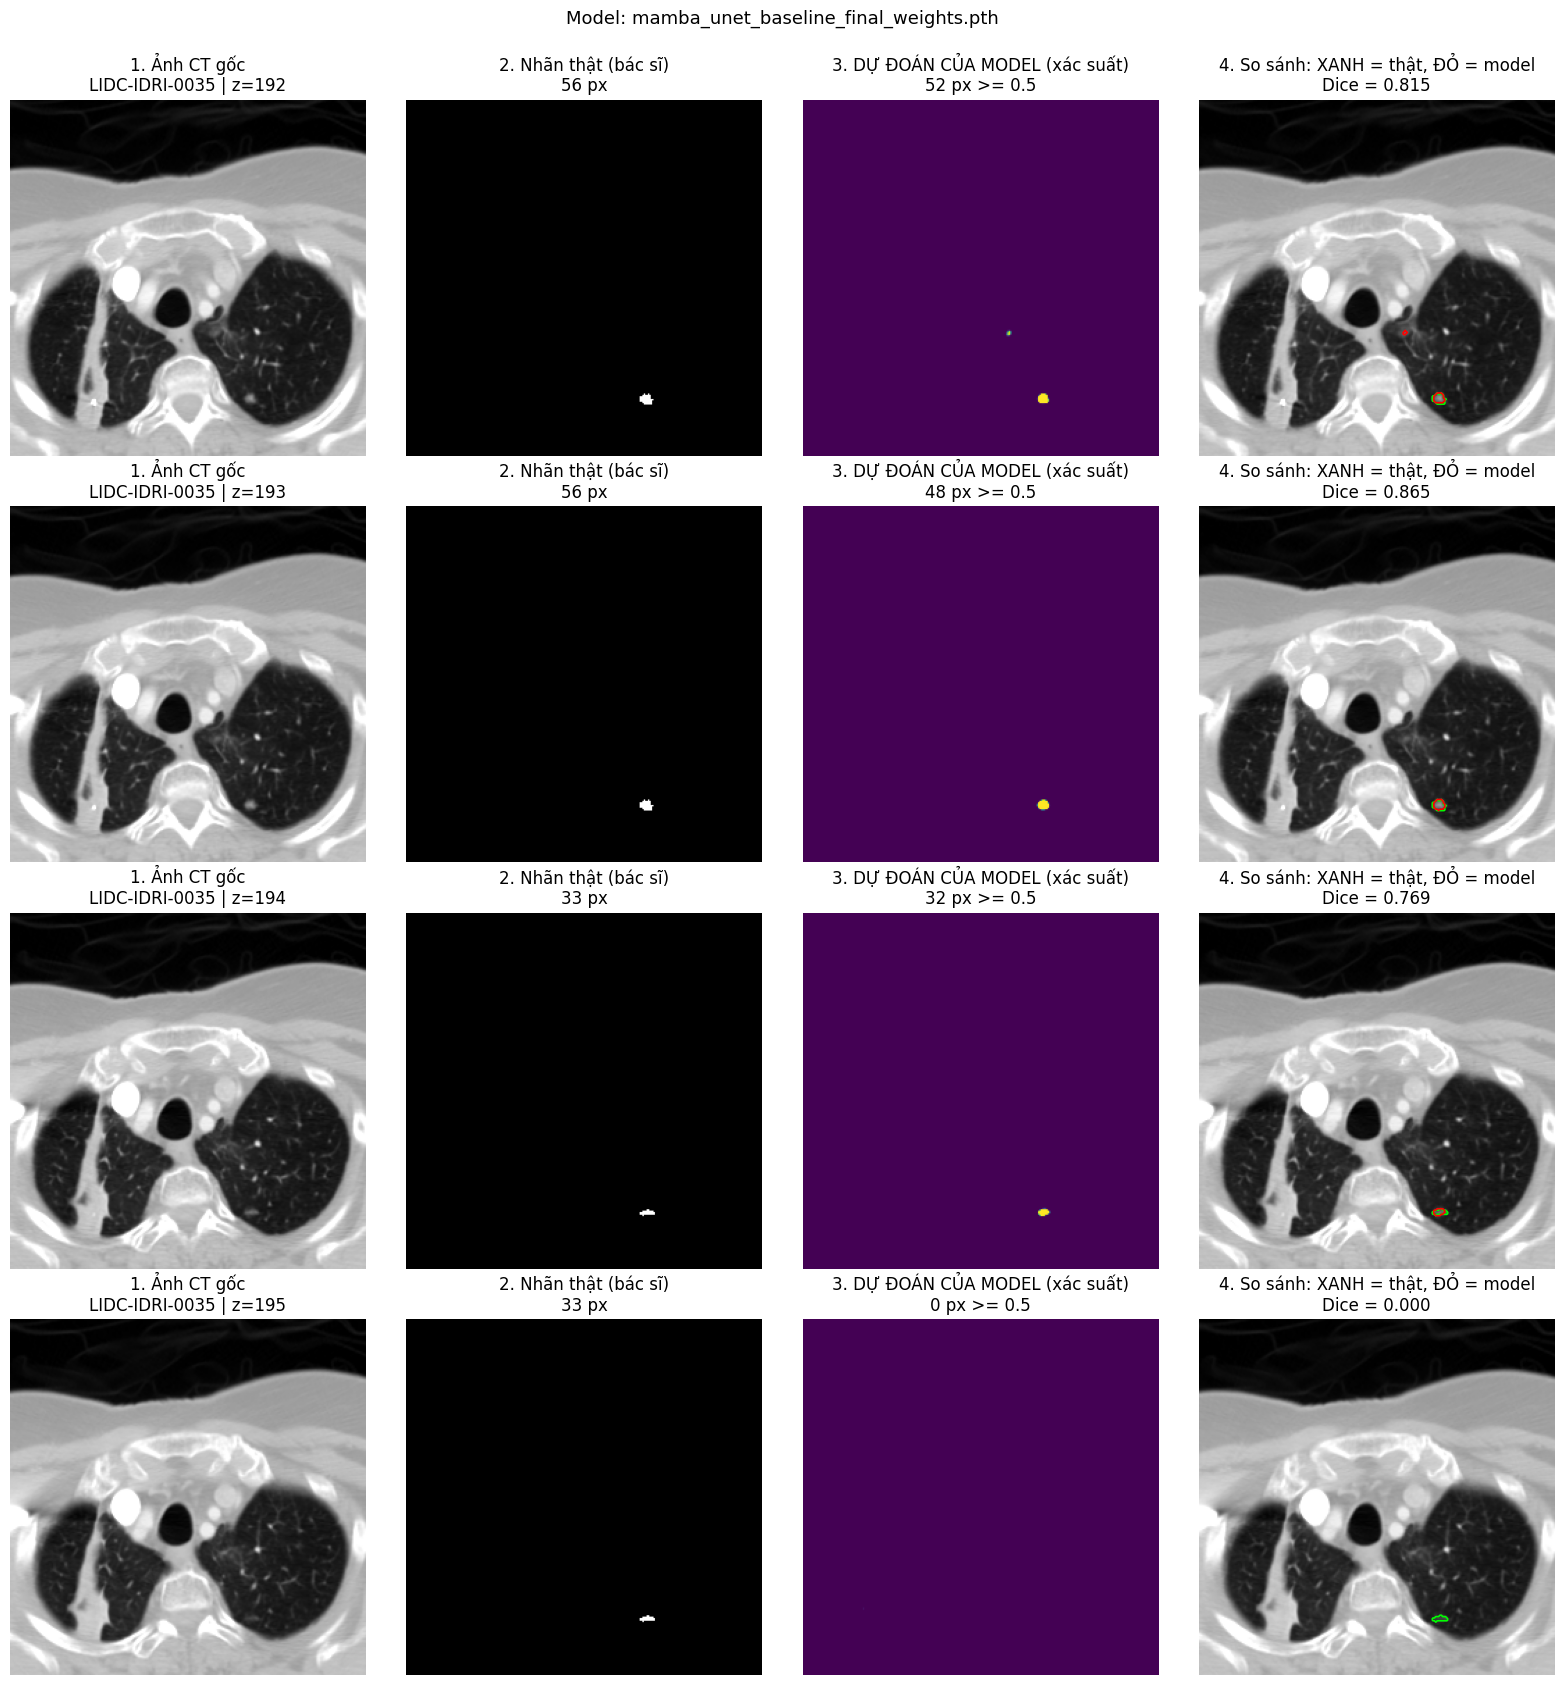

In [18]:
n = len(results)
fig, axes = plt.subplots(n, 4, figsize=(16, 4.2 * n))
axes = np.atleast_2d(axes)
for row, (z, r) in zip(axes, results.items()):
    row[0].imshow(r['img'], cmap='gray')
    row[0].set_title('1. Ảnh CT gốc\n' + PID + ' | z=' + str(z))
    row[1].imshow(r['gt'], cmap='gray', vmin=0, vmax=1)
    row[1].set_title('2. Nhãn thật (bác sĩ)\n' + str(int(r['gt'].sum())) + ' px')
    im = row[2].imshow(r['prob'], cmap='viridis', vmin=0, vmax=1)
    row[2].set_title('3. DỰ ĐOÁN CỦA MODEL (xác suất)\n' + str(int(r['pred'].sum())) + ' px >= ' + str(THRESH))
    row[3].imshow(r['img'], cmap='gray')
    if r['gt'].any():
        row[3].contour(r['gt'], levels=[0.5], colors='lime', linewidths=1.2)
    if r['pred'].any():
        row[3].contour(r['pred'], levels=[0.5], colors='red', linewidths=1.2)
    row[3].set_title('4. So sánh: XANH = thật, ĐỎ = model\nDice = ' + format(r['dice'], '.3f'))
    for a in row:
        a.axis('off')
fig.suptitle('Model: ' + CKPT_PATH.name, fontsize=13, y=1.0)
plt.tight_layout()
plt.show()

## Bước 5 (tùy chọn). Dự đoán cả volume của bệnh nhân `PID` và lưu file

Chỉ chạy khi cần mask 3D. Kết quả lưu ở `model/predictions/<PID>_pred.npy` (uint8, shape `Z x S x S`, 1 = nốt do model dự đoán). Mask đã cắt giữa ảnh theo `image_size`, nên muốn chồng lên ảnh gốc phải cắt ảnh theo `[T0:T0+S, L0:L0+S]`.

In [19]:
BATCH = 8
pred_vol = np.zeros((Z, S, S), dtype=bool)
with torch.no_grad():
    for start in range(0, Z, BATCH):
        zs = list(range(start, min(start + BATCH, Z)))
        xb = np.stack([np.stack([vol[max(z - 1, 0)], vol[z], vol[min(z + 1, Z - 1)]]) for z in zs])
        xb = torch.from_numpy(np.ascontiguousarray(crop(xb))).float().to(DEVICE)
        pred_vol[start:start + len(zs)] = model(xb)[:, 0].float().cpu().numpy() >= THRESH

print(PID, '| Dice 3D (cả volume): %.4f' % dice_np(gt_vol, pred_vol))
print('Số lát model cho là có nốt:', int(pred_vol.reshape(Z, -1).any(1).sum()),
      '| số lát có nốt thật:', len(nodule_z))
if nodule_z:
    print('Dice trung bình trên các lát có nốt thật: %.4f' % np.mean([dice_np(gt_vol[z], pred_vol[z]) for z in nodule_z]))

OUT_DIR = MODEL_DIR / 'predictions'
OUT_DIR.mkdir(exist_ok=True)
out_path = OUT_DIR / (PID + '_pred.npy')
np.save(out_path, pred_vol.astype(np.uint8))
print('Đã lưu:', out_path)

LIDC-IDRI-0035 | Dice 3D (cả volume): 0.0785
Số lát model cho là có nốt: 71 | số lát có nốt thật: 4
Dice trung bình trên các lát có nốt thật: 0.6124
Đã lưu: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/model/predictions/LIDC-IDRI-0035_pred.npy
